# 接近と通過で LC4 を刺激する

`lc4_camera_drive.ipynb` の対応で、球をカメラに投影し、視野に入った LC4 の割合と拡大速度から左右の DNp01 の電流を作る。変えるのは球の半径と速度である。カメラは車のシミュレーションと同じで、対角 58°、16:9、高さ 0.15 m、俯角 12° である。

発火率の定数は `gf_loom_sim.ipynb` のままである。半径 $R$、中心までの距離 $d$ の視角と拡大速度は次である。近づくとき $d$ の減少を正にしてある。

$$
\theta = 2\arctan\frac{R}{d}, \qquad
\dot\theta = \frac{2 R}{d^2 + R^2}\, v_{\mathrm{close}}
$$

視角が 90° になる $d = R$ で接近は止める。正面のその瞬間は $\dot\theta = v / R$ である。画面上の円に入った後シナプスの割合 $f$ を細胞の発火率に掛け、電流はこれまでと同じく側のシナプス合計で割る。$f$ は左右別である。

試す駆動は 3 つ。

- LC4 だけ。拡大速度は 50 rad/s で頭打ちにし、発火率の上限は 80 Hz。基準には刺激しない LPLC2 も入る。
- LC4 と LPLC2 を同じ $f$ で動かす。LPLC2 の列はまだ対応づけていないので、LC4 の被覆をそのまま使う。この電流は、基準を LC4 だけにしたときと数値が同じである。
- 拡大速度を使わず、覆われた細胞を 80 Hz にする。通過は拡大が小さいので、発火率の上限として置く。


In [1]:
from pathlib import Path
import sys

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.feather as feather

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns" / "gf-loom" / "neurons.feather").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from flycar.fov import Scene

DATA = ROOT / "data" / "malecns" / "gf-loom"
CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
R_MAX, R_REF, THETA_DOT_SAT = 80.0, 50.0, 50.0
SCALE = R_MAX / R_REF
TAU_MS, V_THRESHOLD, REFRAC_MS = 5.0, 1.0, 5.0
DT, GEOM_DT = 0.001, 0.005


## 位置とカメラ

細胞の画面位置は `lc4_camera_map.ipynb` と同じである。球の投影は `flycar.fov.project_blob` と同じ式で、画面の左右を LC4 の $u$、上下を $v$ に置く。


In [2]:
def image_uv(ab, side, left_ab, right_ab):
    """u is 0 at the left edge and 1 at the right edge. v is 0 at the top."""
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


pack = np.load(CACHE)
syn_side = pack["side"]
syn_u, syn_v = image_uv(pack["ab"], syn_side, pack["left_ab"], pack["right_ab"])
order = np.argsort(pack["body"], kind="mergesort")
syn_body = pack["body"][order]
syn_u = syn_u[order]
syn_v = syn_v[order]
syn_side = syn_side[order]
cuts = np.flatnonzero(np.diff(syn_body)) + 1
starts = np.r_[0, cuts]
cell_n = np.diff(np.r_[starts, len(syn_body)])
cell_side = syn_side[starts]
cell_id = syn_body[starts]

neurons = feather.read_table(DATA / "neurons.feather").to_pandas()
edges = feather.read_table(DATA / "edges.feather").to_pandas()
lc4 = neurons.loc[neurons.type == "LC4", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_pre", "side": "side_pre"}
)
gf = neurons.loc[neurons.type == "DNp01", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_post", "side": "side_post"}
)
lplc = neurons.loc[neurons.type == "LPLC2", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_pre", "side": "side_pre"}
)
onto = edges.merge(lc4, on="body_pre").merge(gf, on="body_post")
lplc_onto = edges.merge(lplc, on="body_pre").merge(gf, on="body_post")
if not (onto.side_pre == onto.side_post).all():
    raise RuntimeError("対側への LC4 → DNp01 がある。")
weight_of = dict(zip(onto.body_pre.astype(np.int64), onto.weight.astype(np.float64)))
cell_w = np.array([weight_of[int(i)] for i in cell_id])
lc4_sum = np.array([cell_w[cell_side == code].sum() for code in (0, 1)])
lplc_sum = np.array([
    float(lplc_onto.loc[lplc_onto.side_post == name, "weight"].sum()) for name in ("L", "R")
])
lc4_of_ref = lc4_sum / (lc4_sum + lplc_sum)

scene = Scene()
hfov, vfov = scene.fovs()
pitch = float(np.deg2rad(scene.pitch_deg))
cam = np.array([0.0, 0.0, scene.cam_h])
forward = np.array([1.0, 0.0, 0.0])
left = np.array([0.0, 1.0, 0.0])
up = np.array([0.0, 0.0, 1.0])
optical = forward * np.cos(pitch) - up * np.sin(pitch)
cam_up = forward * np.sin(pitch) + up * np.cos(pitch)
cam_right = -left
tan_h = float(np.tan(hfov / 2.0))
tan_v = float(np.tan(vfov / 2.0))
print(
    f"水平 {np.rad2deg(hfov):.1f}°  垂直 {np.rad2deg(vfov):.1f}°  "
    f"LC4 が基準に占める割合  左 {lc4_of_ref[0]:.3f}  右 {lc4_of_ref[1]:.3f}"
)

check = None


水平 51.6°  垂直 30.4°  LC4 が基準に占める割合  左 0.589  右 0.537


## 電流

$f$ はその側の LC4 の重みのうち、球の投影に入った割合である。拡大速度が負のときは 0 にする。膜は時定数 5 ms、閾値 1、不応期 5 ms で、幾何は 5 ms ごとに更新して 1 ms ずつ積む。


In [3]:
def side_fraction(center_u, center_v, radius_u, radius_v):
    if (
        radius_u < 1e-8
        or radius_v < 1e-8
        or center_u + radius_u < 0.0
        or center_u - radius_u > 1.0
        or center_v + radius_v < 0.0
        or center_v - radius_v > 1.0
    ):
        return np.zeros(2)
    inside = ((syn_u - center_u) / radius_u) ** 2 + ((syn_v - center_v) / radius_v) ** 2 <= 1.0
    hit = np.add.reduceat(inside.astype(np.float64), starts)
    frac = hit / cell_n
    share = np.zeros(2)
    for index, code in enumerate((0, 1)):
        chosen = cell_side == code
        share[index] = float(np.dot(cell_w[chosen], frac[chosen]) / lc4_sum[index])
    return share


# 以前の静止した円。左 0.132、右 0。
still = side_fraction(0.25, 0.50, 0.10, 0.10)
if abs(still[0] - 0.132) > 0.005 or still[1] != 0.0:
    raise RuntimeError(f"静止円の割合が以前と違う: {still}")


def project(pos, radius):
    rel = pos - cam
    depth = float(np.dot(rel, optical))
    if depth <= 1e-4:
        return None
    nx = float(np.dot(rel, cam_right) / depth) / tan_h
    ny = float(np.dot(rel, cam_up) / depth) / tan_v
    return (
        (nx + 1.0) / 2.0,
        (1.0 - ny) / 2.0,
        (radius / depth) / tan_h / 2.0,
        (radius / depth) / tan_v / 2.0,
    )


def expansion(pos, velocity, radius):
    rel = pos - cam
    dist = float(np.linalg.norm(rel))
    theta = 2.0 * np.arctan(radius / dist)
    closing = -float(np.dot(rel, velocity)) / dist
    theta_dot = 2.0 * radius * closing / (dist * dist + radius * radius)
    return theta, max(theta_dot, 0.0)


def lif_result(drive):
    v = 0.0
    silent_until = 0
    refrac_steps = int(round(REFRAC_MS / (DT * 1000)))
    step = (DT * 1000) / TAU_MS
    count = 0
    peak = 0.0
    voltage = np.empty(len(drive))
    for i, value in enumerate(drive):
        if i < silent_until:
            v = 0.0
            voltage[i] = 0.0
            continue
        v += step * (-v + float(value))
        peak = max(peak, v)
        if v >= V_THRESHOLD:
            voltage[i] = V_THRESHOLD
            count += 1
            v = 0.0
            silent_until = i + refrac_steps
        else:
            voltage[i] = v
    return count, peak, voltage


def currents_from(share, theta_dot):
    clip = np.clip(theta_dot / THETA_DOT_SAT, 0.0, 1.0)
    return {
        "LC4": share * lc4_of_ref * clip[:, None] * SCALE,
        "両方": share * clip[:, None] * SCALE,
        "被覆": share * SCALE,
    }


def simulate(positions, velocity, radius):
    n = len(positions)
    share = np.zeros((n, 2))
    theta = np.zeros(n)
    theta_dot = np.zeros(n)
    for i, pos in enumerate(positions):
        theta[i], theta_dot[i] = expansion(pos, velocity, radius)
        projected = project(pos, radius)
        if projected is not None:
            share[i] = side_fraction(*projected)
    series = currents_from(share, theta_dot)
    repeats = int(round(GEOM_DT / DT))
    summary = {
        "視角": float(np.rad2deg(theta.max())),
        "拡大速度": float(theta_dot.max()),
        "割合左": float(share[:, 0].max()),
        "割合右": float(share[:, 1].max()),
    }
    detail = {"share": share, "theta": theta, "theta_dot": theta_dot, "current": {}, "voltage": {}}
    for name, current in series.items():
        expanded = np.repeat(current, repeats, axis=0)
        left_n, _, left_v = lif_result(expanded[:, 0])
        right_n, _, right_v = lif_result(expanded[:, 1])
        summary[f"{name}電流左"] = float(current[:, 0].max())
        summary[f"{name}電流右"] = float(current[:, 1].max())
        summary[f"{name}スパイク左"] = left_n
        summary[f"{name}スパイク右"] = right_n
        detail["current"][name] = current
        detail["voltage"][name] = np.column_stack([left_v, right_v])
    detail["time"] = np.arange(repeats * n) * DT
    return summary, detail


def approach_path(radius, speed, offset, window=0.40):
    samples = int(round(window / GEOM_DT)) + 1
    distance = np.linspace(radius + speed * window, radius, samples)
    positions = cam + optical * distance[:, None] + left * offset
    return positions, -optical * speed


def passage_path(radius, speed, distance):
    """画像の左の外から右の外へ、光軸から distance の面を横切る。"""
    half = distance * tan_h + radius + 0.05
    samples = int(round(2.0 * half / speed / GEOM_DT)) + 1
    lateral = np.linspace(half, -half, samples)
    positions = cam + optical * distance + left * lateral[:, None]
    return positions, -left * speed


## 接近

球は光軸に沿って近づき、視角 90° で止める。正面はオフセット 0、左からと右からはカメラ左方向へ 0.15 m ずらす。0.15 m は、0.5 m 先で水平画角の内側にまだ残る距離である。


In [4]:
RADII = [0.03, 0.05, 0.08, 0.12, 0.20, 0.40]
SPEEDS = [0.5, 1.0, 2.0, 4.0, 8.0]
approach_rows = []
for offset, where in ((0.0, "正面"), (0.15, "左"), (-0.15, "右")):
    for radius in RADII:
        for speed in SPEEDS:
            positions, velocity = approach_path(radius, speed, offset)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"経路": where, "半径": radius, "速度": speed})
            approach_rows.append(summary)

approach = pd.DataFrame(approach_rows)
show = approach.loc[
    approach["経路"].eq("正面")
    & (
        (approach["両方スパイク左"] + approach["両方スパイク右"] + approach["LC4スパイク左"] > 0)
        | approach["速度"].isin([1.0, 4.0])
    ),
    [
        "経路", "半径", "速度", "視角", "拡大速度",
        "LC4電流左", "LC4スパイク左",
        "両方電流左", "両方スパイク左", "両方スパイク右",
        "被覆スパイク左",
    ],
]
print("正面。スパイクが出た行と、速度 1 m/s と 4 m/s")
print(show.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
print()
side = approach.loc[approach["経路"].ne("正面")]
hit = side.loc[(side["被覆スパイク左"] + side["被覆スパイク右"]) > 0, ["経路", "半径", "速度", "視角", "拡大速度", "割合左", "割合右", "両方電流左", "両方スパイク左", "被覆スパイク左", "被覆スパイク右"]]
print("左右に 0.15 m ずらした接近のうち、被覆で発火したもの")
print(hit.drop_duplicates(["経路", "半径"]).to_string(index=False, float_format=lambda value: f"{value:.2f}"))
print(
    "LC4 だけのスパイク合計",
    int(approach["LC4スパイク左"].sum() + approach["LC4スパイク右"].sum()),
)


正面。スパイクが出た行と、速度 1 m/s と 4 m/s
経路   半径   速度    視角   拡大速度  LC4電流左  LC4スパイク左  両方電流左  両方スパイク左  両方スパイク右  被覆スパイク左
正面 0.03 1.00 90.00  33.33    0.63         0   1.07        0        0        7
正面 0.03 2.00 90.00  66.67    0.94         0   1.60        2        2        4
正面 0.03 4.00 90.00 133.33    0.94         0   1.60        2        2        2
正面 0.03 8.00 90.00 266.67    0.94         0   1.60        1        1        1
正面 0.05 1.00 90.00  20.00    0.38         0   0.64        0        0       12
正面 0.05 2.00 90.00  40.00    0.75         0   1.28        1        1        6
正面 0.05 4.00 90.00  80.00    0.94         0   1.60        2        2        3
正面 0.05 8.00 90.00 160.00    0.94         0   1.60        2        2        2
正面 0.08 1.00 90.00  12.50    0.24         0   0.40        0        0       18
正面 0.08 4.00 90.00  50.00    0.94         0   1.60        1        1        5
正面 0.08 8.00 90.00 100.00    0.94         0   1.60        2        2        3
正面 0.12 1.00 90.00   8.33    0.16 

## 通過

球は光軸から一定の距離の面を、画像の左の外から右の外へ一定速度で横切る。距離は 0.30 m、0.50 m、1.0 m。拡大速度はこの横断では小さい。


In [5]:
DISTANCES = [0.30, 0.50, 1.00]
PASS_SPEEDS = [0.5, 2.0, 8.0]
passage_rows = []
for distance in DISTANCES:
    for radius in RADII:
        for speed in PASS_SPEEDS:
            positions, velocity = passage_path(radius, speed, distance)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"距離": distance, "半径": radius, "速度": speed})
            passage_rows.append(summary)

passage = pd.DataFrame(passage_rows)
peak = (
    passage.groupby(["距離", "半径"], as_index=False)
    .agg(
        視角=("視角", "max"),
        拡大速度=("拡大速度", "max"),
        割合左=("割合左", "max"),
        LC4電流=("LC4電流左", "max"),
        両方電流=("両方電流左", "max"),
        被覆電流=("被覆電流左", "max"),
        LC4スパイク=("LC4スパイク左", "sum"),
        両方スパイク=("両方スパイク左", "sum"),
        被覆スパイク=("被覆スパイク左", "sum"),
    )
)
print(peak.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
print(
    "通過で LC4 または両方の拡大速度モデルが発火した行",
    int((passage["LC4スパイク左"] + passage["両方スパイク左"] + passage["LC4スパイク右"] + passage["両方スパイク右"]).sum()),
)


  距離   半径     視角  拡大速度  割合左  LC4電流  両方電流  被覆電流  LC4スパイク  両方スパイク  被覆スパイク
0.30 0.03  11.42  2.04 0.25   0.01  0.01  0.41        0       0       0
0.30 0.05  18.92  3.35 0.62   0.02  0.04  1.00        0       0       0
0.30 0.08  29.86  5.20 0.94   0.06  0.11  1.50        0       0      28
0.30 0.12  43.60  7.41 1.00   0.11  0.19  1.60        0       0      56
0.30 0.20  67.38 10.66 1.00   0.20  0.33  1.60        0       0     103
0.30 0.40 106.26 13.29 1.00   0.25  0.43  1.60        0       0     221
0.50 0.03   6.87  0.73 0.10   0.00  0.00  0.16        0       0       0
0.50 0.05  11.42  1.22 0.25   0.00  0.01  0.41        0       0       0
0.50 0.08  18.18  1.94 0.59   0.01  0.02  0.94        0       0       0
0.50 0.12  26.99  2.85 0.89   0.03  0.05  1.42        0       0      37
0.50 0.20  43.60  4.46 1.00   0.07  0.12  1.60        0       0      91
0.50 0.40  77.32  7.02 1.00   0.13  0.22  1.60        0       0     211
1.00 0.03   3.44  0.18 0.03   0.00  0.00  0.05        0       0 

## 波形

左は正面接近で、半径 5 cm、2 m/s。接触直前の拡大速度は 40 rad/s である。右は 0.50 m 先の通過で、半径 12 cm、1 m/s。細線が LC4 だけ、太線が LC4 と LPLC2 を同じ割合にしたもの、破線が被覆を 80 Hz にしたもの。膜は左の DNp01 である。


正面 5 cm、2 m/s  視角 90°  拡大速度 40.0  LC4 0  両方 1  被覆 6
通過 0.50 m、12 cm、1 m/s  視角 27°  拡大速度 0.4  LC4 0  両方 0  被覆 14


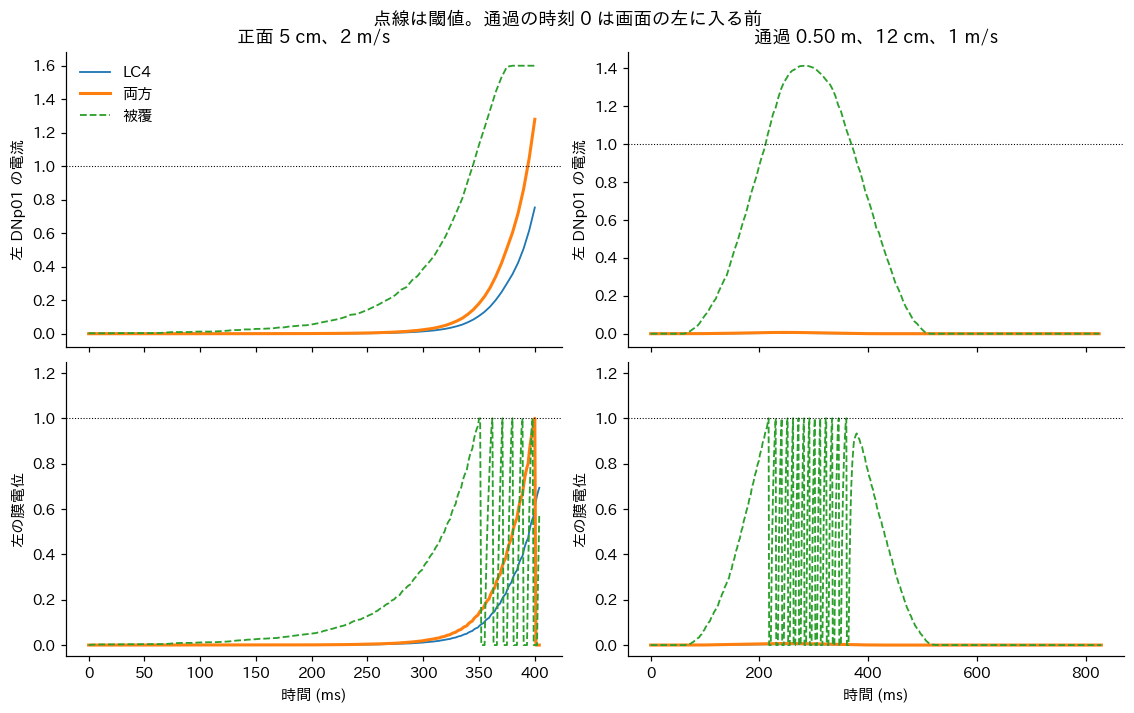

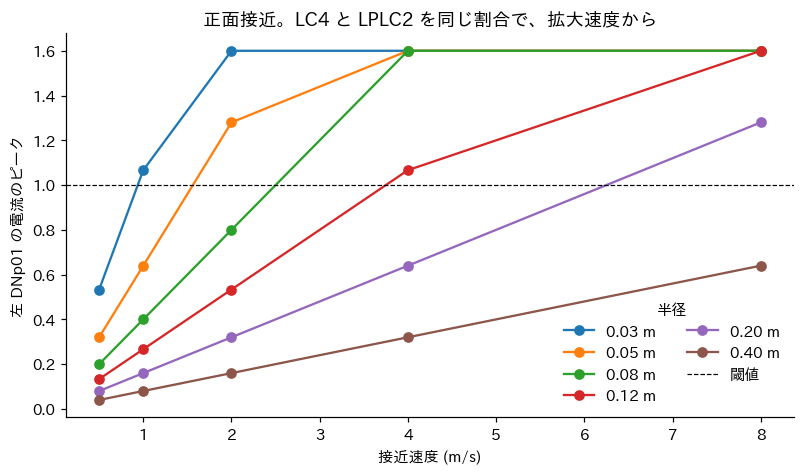

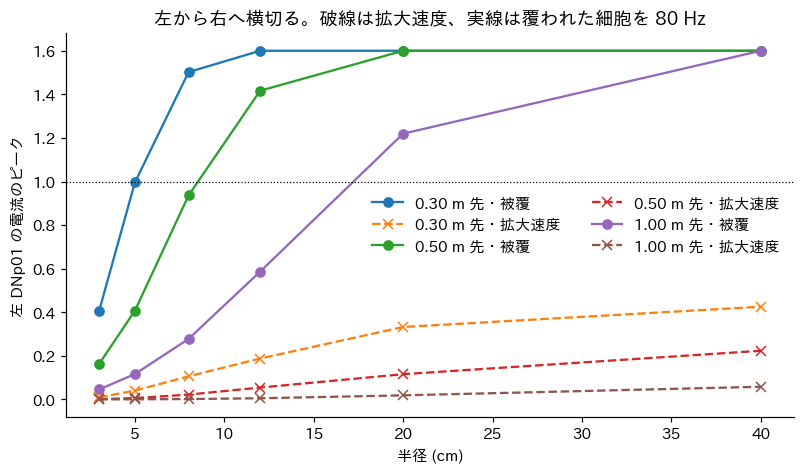

In [6]:
examples = []
for label, positions, velocity, radius in (
    ("正面 5 cm、2 m/s", *approach_path(0.05, 2.0, 0.0), 0.05),
    ("通過 0.50 m、12 cm、1 m/s", *passage_path(0.12, 1.0, 0.50), 0.12),
):
    summary, detail = simulate(positions, velocity, radius)
    examples.append((label, summary, detail))
    print(
        f"{label}  視角 {summary['視角']:.0f}°  拡大速度 {summary['拡大速度']:.1f}  "
        f"LC4 {summary['LC4スパイク左']}  両方 {summary['両方スパイク左']}  被覆 {summary['被覆スパイク左']}"
    )

fig, axes = plt.subplots(2, 2, figsize=(10.2, 6.2), sharex="col", constrained_layout=True)
styles = (("LC4", 1.2, "-"), ("両方", 2.0, "-"), ("被覆", 1.2, "--"))
for column, (label, summary, detail) in enumerate(examples):
    time_ms = np.arange(len(detail["current"]["LC4"])) * GEOM_DT * 1000
    membrane_ms = detail["time"] * 1000
    for name, width, linestyle in styles:
        axes[0, column].plot(time_ms, detail["current"][name][:, 0], lw=width, ls=linestyle, label=name)
        axes[1, column].plot(membrane_ms, detail["voltage"][name][:, 0], lw=width, ls=linestyle, label=name)
    axes[0, column].axhline(1.0, color="k", lw=0.7, ls=":")
    axes[1, column].axhline(1.0, color="k", lw=0.7, ls=":")
    axes[0, column].set_title(label)
    axes[0, column].set_ylabel("左 DNp01 の電流")
    axes[1, column].set_ylabel("左の膜電位")
    axes[1, column].set_xlabel("時間 (ms)")
    axes[1, column].set_ylim(-0.05, 1.25)
axes[0, 0].legend(frameon=False, loc="upper left")
for ax in axes.ravel():
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("点線は閾値。通過の時刻 0 は画面の左に入る前", y=1.02)
plt.show()

front = approach.loc[approach["経路"].eq("正面")]
fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
for radius, part in front.groupby("半径"):
    ax.plot(part["速度"], part["両方電流左"], marker="o", label=f"{radius:.2f} m")
ax.axhline(1.0, color="k", lw=0.8, ls="--", label="閾値")
ax.set_xlabel("接近速度 (m/s)")
ax.set_ylabel("左 DNp01 の電流のピーク")
ax.set_title("正面接近。LC4 と LPLC2 を同じ割合で、拡大速度から")
ax.legend(frameon=False, title="半径", ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
for distance, part in peak.groupby("距離"):
    ax.plot(part["半径"] * 100, part["被覆電流"], marker="o", label=f"{distance:.2f} m 先・被覆")
    ax.plot(part["半径"] * 100, part["両方電流"], marker="x", ls="--", label=f"{distance:.2f} m 先・拡大速度")
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("半径 (cm)")
ax.set_ylabel("左 DNp01 の電流のピーク")
ax.set_title("左から右へ横切る。破線は拡大速度、実線は覆われた細胞を 80 Hz")
ax.legend(frameon=False, ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


## 読み方

LC4 だけを、拡大速度で、80 Hz の頭打ちにして駆動したときは、正面接近も左右に 0.15 m ずらした接近も、左から右への通過も、スパイクが 0 だった。正面で画面を埋め切っても電流は左 0.94、右 0.86 で止まる。速度を上げると頭打ちに早く届くだけで、上限は増えない。

正面接近で LC4 と LPLC2 を同じ割合だけ発火させると、接触直前の拡大速度が 40 rad/s 以上のときに左右とも発火する。その瞬間の拡大速度は速度/半径なので、半径 3 cm なら 2 m/s、半径 5 cm なら 2 m/s、半径 8 cm なら 4 m/s、半径 12 cm なら 8 m/s、半径 20 cm なら 8 m/s である。半径 40 cm は 8 m/s でも 20 rad/s、電流 0.64 で届かない。半径 12 cm の 4 m/s は拡大速度 33 rad/s、電流のピーク 1.07 だが、閾値を超えている時間が約 2 ms で、膜の 5 ms では 1 に届かなかった。40 rad/s ではその時間が約 6 ms になり、1 回発火する。

この「LPLC2 も同じ割合」は、基準を刺激している LC4 だけに置き換えたときの電流と数値が同じである。LPLC2 の列はまだ対応づけていない。黙っている LPLC2 を分母に残す今の式では、正面でも発火しない。

左右に 0.15 m ずらすと、水平 52° の画角から外れる。視角は 90° まで届かず、拡大速度は半径 20 cm を 8 m/s にしても 25 rad/s 程度で、拡大速度の式では発火しない。覆われた細胞を 80 Hz にする上限では、半径 12 cm 以上で近い側だけが発火する。左からの接近は左の DNp01 だけ、右からは右だけである。半径 40 cm は両側が画面に入り、両方が発火する。0.5 m/s から 8 m/s まで、この分かれ方は残る。

通過は拡大速度が小さい。いちばん速い例でも 13 rad/s（半径 40 cm、0.30 m 先、8 m/s）で、電流は 0.43 を超えない。速度を 0.5、2、8 m/s に変えても、LC4 だけでも両方でも発火は 0 だった。覆われた細胞を 80 Hz にする上限では、片側の重みの約 6 割を超えると発火する。0.30 m 先は半径 8 cm（視角 30°）、0.50 m 先は半径 12 cm（視角 27°）、1.0 m 先は半径 20 cm（視角 23°）。直前の大きさ、0.30 m 先の半径 5 cm は電流 1.00 ちょうどで、膜は 1 に届かない。横切るあいだは、球がいる側の DNp01 が順に発火する。
